# Statistics for Data Science: Customer Analytics Project

**Scenario:** An e-commerce company wants to understand delivery performance, order values, and customer satisfaction.

This is a synthetic teaching dataset with 30 observations. It is designed to demonstrate statistical techniques, not to support real business decisions. (Dataset generated by ChatGPT)


## Questions
- What is typical, and how spread out are delivery times and order values?
- Are there potential outliers or skewed distributions?
- How do PMF, density/PDF, and CDF differ?
- How do binomial and normal models work?
- What does the Central Limit Theorem tell us about sample means?
- How do variance, standard deviation, covariance, correlation, and CV help?

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

data = {
    "customer_id": list(range(1001, 1031)),
    "delivery_days": [2,3,3,4,4,4,5,5,5,5,6,6,6,6,7,7,7,8,8,8,9,9,10,10,11,12,12,13,15,28],
    "order_value_inr": [450,520,600,650,700,750,800,850,900,950,1000,1050,1100,1150,1200,1250,1300,1350,1400,1450,1500,1550,1600,1700,1800,1900,2100,2300,2600,5000],
    "satisfaction_rating": [3,4,4,5,4,3,5,4,4,5,3,4,5,4,4,5,2,4,5,3,4,5,4,4,5,3,4,5,2,1],
    "positive_rating": [0,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,1,1,0,1,1,1,1,1,0,1,1,0,0],
    "promo_used": [1,0,1,0,0,1,1,0,1,0,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1],
    "customer_type": ["New" if i % 3 == 0 else "Returning" for i in range(30)]
}

In [9]:
df = pd.DataFrame(data)
display(df.head())

,customer_id,delivery_days,order_value_inr,satisfaction_rating,positive_rating,promo_used,customer_type
0,1001,2,450,3,0,1,New
1,1002,3,520,4,1,0,Returning
2,1003,3,600,4,1,1,Returning
3,1004,4,650,5,1,0,New
4,1005,4,700,4,1,0,Returning


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   customer_id          30 non-null     int64 
 1   delivery_days        30 non-null     int64 
 2   order_value_inr      30 non-null     int64 
 3   satisfaction_rating  30 non-null     int64 
 4   positive_rating      30 non-null     int64 
 5   promo_used           30 non-null     int64 
 6   customer_type        30 non-null     object
dtypes: int64(6), object(1)
memory usage: 1.8+ KB


In [15]:
print("shape: ", df.shape)

shape:  (30, 7)


In [27]:
df.dtypes.to_frame("Data type")

,Data type
customer_id,int64
delivery_days,int64
order_value_inr,int64
satisfaction_rating,int64
positive_rating,int64
promo_used,int64
customer_type,object


In [25]:
df.dtypes

customer_id             int64
delivery_days           int64
order_value_inr         int64
satisfaction_rating     int64
positive_rating         int64
promo_used              int64
customer_type          object
dtype: object

In [37]:
df.isna().sum().to_frame("missing value")

,missing value
customer_id,0
delivery_days,0
order_value_inr,0
satisfaction_rating,0
positive_rating,0
promo_used,0
customer_type,0


In [39]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_id,30.0,1015.500000,8.803408,1001.0,1008.25,1015.5,1022.75,1030.0
delivery_days,30.0,7.933333,4.961461,2.0,5.00,7.0,9.75,28.0
order_value_inr,30.0,1382.333333,864.681258,450.0,862.50,1225.0,1587.50,5000.0
satisfaction_rating,30.0,3.900000,1.028893,1.0,3.25,4.0,5.00,5.0
positive_rating,30.0,0.733333,0.449776,0.0,0.25,1.0,1.00,1.0
promo_used,30.0,0.500000,0.508548,0.0,0.00,0.5,1.00,1.0


### Variable types
- `delivery_days`: discrete numeric (recorded in whole days).
- `order_value_inr`: treated as continuous for analysis.
- `satisfaction_rating`: discrete ordinal rating from 1 to 5.
- `positive_rating` and `promo_used`: binary discrete variables.
- `customer_type`: categorical.

The variable type affects which summaries and probability models are appropriate.

In [42]:
df.head()

,customer_id,delivery_days,order_value_inr,satisfaction_rating,positive_rating,promo_used,customer_type
0,1001,2,450,3,0,1,New
1,1002,3,520,4,1,0,Returning
2,1003,3,600,4,1,1,Returning
3,1004,4,650,5,1,0,New
4,1005,4,700,4,1,0,Returning


## 2. Mean, median, and mode
The mean is sensitive to extreme values; the median is more robust; the mode identifies the most frequent value(s).

In [49]:
for x in ['delivery_days','order_value_inr','satisfaction_rating']:
    print(f"\\n{x}")
    print("mean:", df[x].mean())
    print("median:", df[x].median())
    print("mode:", df[x].mode().tolist())

\ndelivery_days
mean: 7.933333333333334
median: 7.0
mode: [5, 6]
\norder_value_inr
mean: 1382.3333333333333
median: 1225.0
mode: [450, 520, 600, 650, 700, 750, 800, 850, 900, 950, 1000, 1050, 1100, 1150, 1200, 1250, 1300, 1350, 1400, 1450, 1500, 1550, 1600, 1700, 1800, 1900, 2100, 2300, 2600, 5000]
\nsatisfaction_rating
mean: 3.9
median: 4.0
mode: [4]


## 3. Quartiles, IQR, and outlier fences

Q1 is the 25th percentile, Q2 is the median, and Q3 is the 75th percentile. The IQR describes the middle 50% of observations.

\[
IQR=Q3-Q1
\]

\[
Lower\ fence=Q1-1.5(IQR),\quad Upper\ fence=Q3+1.5(IQR)
\]

Values outside the fences are **potential outliers**, not automatically errors.

,Delivery days
Q1,5.0
Q2,7.0
Q3,9.75
IQR,4.75
lower fence,-2.125
upper fence,16.875
potential outlier,[28]


,Order value (INR)
Q1,862.5
Q2,1225.0
Q3,1587.5
IQR,725.0
lower fence,-225.0
upper fence,2675.0
potential outlier,[5000]


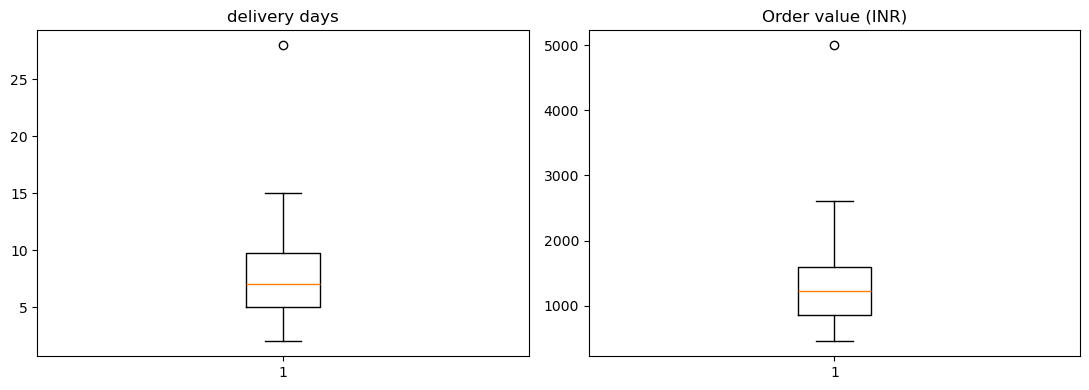

In [64]:
def iqr_summary(series):
    q1,q2,q3 = series.quantile([0.25,0.50,0.75])
    iqr = q3-q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier = series[(series < lower) | (series > upper)].tolist()
    return pd.Series({"Q1": q1, "Q2": q2,"Q3": q3, "IQR": iqr,
           "lower fence": lower,"upper fence": upper,
           "potential outlier": outlier})

display(iqr_summary(df["delivery_days"]).to_frame("Delivery days"))
display(iqr_summary(df["order_value_inr"]).to_frame("Order value (INR)"))

fig,axes = plt.subplots(1,2, figsize =(11,4))
axes[0].boxplot(df['delivery_days'])
axes[0].set_title("delivery days")
axes[1].boxplot(df["order_value_inr"])
axes[1].set_title("Order value (INR)")
plt.tight_layout()
plt.show()

**Why IQR?** It summarizes the middle half of the data and is less affected by extreme values than the range or standard deviation. Investigate flagged observations before deciding whether to correct or exclude them.

## 4. Histograms and skewness
A histogram shows how observations are distributed across bins. Right/positive skew means a longer tail toward larger values; left/negative skew means a longer tail toward smaller values.

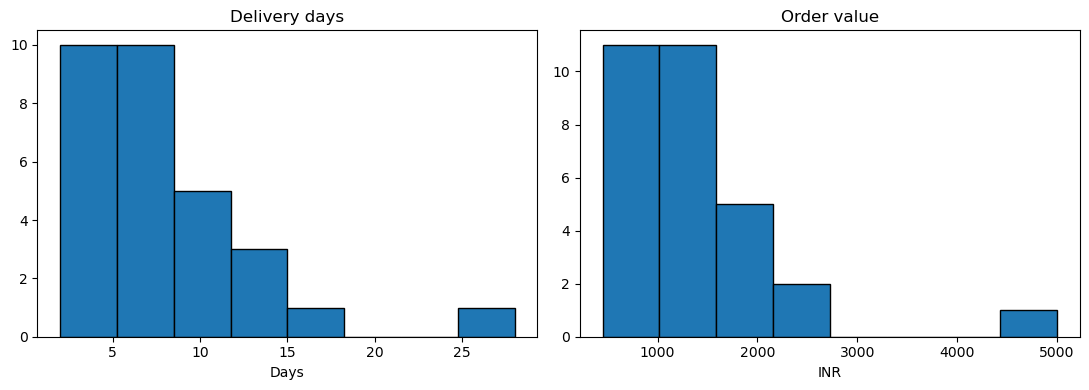

Delivery days skewness: 2.415
Order value skewness: 2.685


In [68]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["delivery_days"], bins=8, edgecolor="black")
axes[0].set_title("Delivery days")
axes[0].set_xlabel("Days")
axes[1].hist(df["order_value_inr"], bins=8, edgecolor="black")
axes[1].set_title("Order value")
axes[1].set_xlabel("INR")
plt.tight_layout()
plt.show()
print("Delivery days skewness:", round(df["delivery_days"].skew(), 3))
print("Order value skewness:", round(df["order_value_inr"].skew(), 3))

**Interpretation:** Positive skewness suggests a long right tail. A few very late deliveries or high-value orders can pull the mean upward. Report median and IQR alongside mean and SD when data are skewed.

## 5. PMF for a discrete variable
An empirical probability mass function gives each possible discrete value's observed proportion. Here we use satisfaction ratings.

,Probability
satisfaction_rating,
1,0.033333
2,0.066667
3,0.166667
4,0.433333
5,0.300000


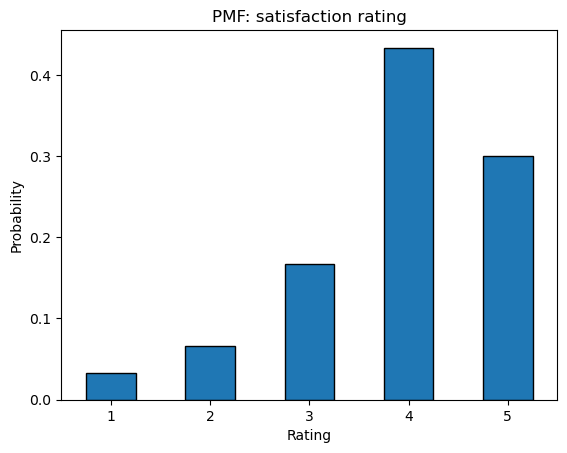

In [72]:
pmf = df["satisfaction_rating"].value_counts(normalize=True).sort_index()
display(pmf.rename("Probability").to_frame())
pmf.plot(kind="bar", edgecolor="black")
plt.title("PMF: satisfaction rating")
plt.xlabel("Rating")
plt.ylabel("Probability")
plt.xticks(rotation=0)
plt.show()

In [74]:
pmf = df["satisfaction_rating"].value_counts(normalize=True).sort_index()

In [76]:
pmf

satisfaction_rating
1    0.033333
2    0.066667
3    0.166667
4    0.433333
5    0.300000
Name: proportion, dtype: float64

**Why PMF?** It answers questions such as “What proportion gave rating 4?” Probabilities across all rating categories sum to 1. These are sample proportions, not guaranteed population probabilities.

## 6. PDF / density for a continuous variable
For continuous data, probability is represented by area under a density curve over an interval. The KDE is a smoothed estimate of density, not necessarily the true PDF.

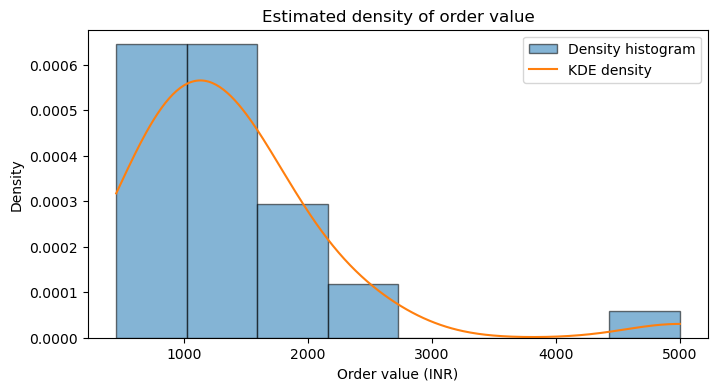

In [82]:
x = df["order_value_inr"]
grid = np.linspace(x.min(), x.max(), 300)
kde = stats.gaussian_kde(x)
plt.figure(figsize=(8, 4))
plt.hist(x, bins=8, density=True, alpha=0.55, edgecolor="black", label="Density histogram")
plt.plot(grid, kde(grid), label="KDE density")
plt.title("Estimated density of order value")
plt.xlabel("Order value (INR)")
plt.ylabel("Density")
plt.legend()
plt.show()

**Interpretation:** The density plot shows where order values concentrate. Density height at one point is not a probability; the area over a range is the probability. Inspect the shape before assuming normality.

## 7. CDF: cumulative distribution function
The empirical CDF gives the proportion of observations less than or equal to x: F(x) = P(X ≤ x).

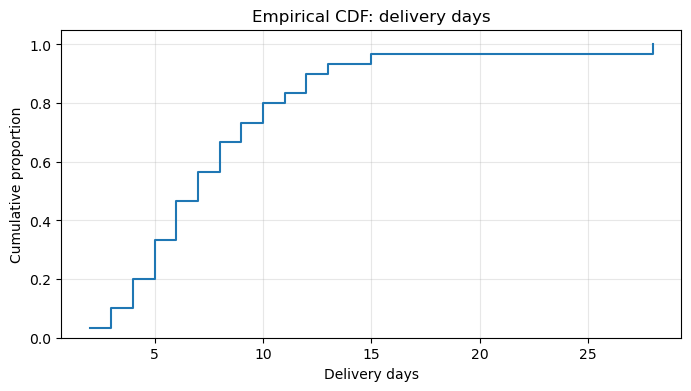

Delivered within 5 days: 33.3%
Delivered within 7 days: 56.7%
Delivered within 10 days: 80.0%


In [86]:
delivery = np.sort(df["delivery_days"].to_numpy())
ecdf = np.arange(1, len(delivery) + 1) / len(delivery)
plt.figure(figsize=(8, 4))
plt.step(delivery, ecdf, where="post")
plt.title("Empirical CDF: delivery days")
plt.xlabel("Delivery days")
plt.ylabel("Cumulative proportion")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.show()
for t in [5, 7, 10]:
    print(f"Delivered within {t} days: {(df['delivery_days'] <= t).mean():.1%}")

## 8. Binomial distribution: exactly 3 positive ratings out of 5
Assume n=5 independent customers, each with a constant probability p=0.70 of giving a positive rating. This is a scenario assumption for learning, not a population estimate from this tiny dataset.

P(exactly 3 positives) = 0.3087 (30.87%)
P(at least 3 positives) = 0.8369 (83.69%)


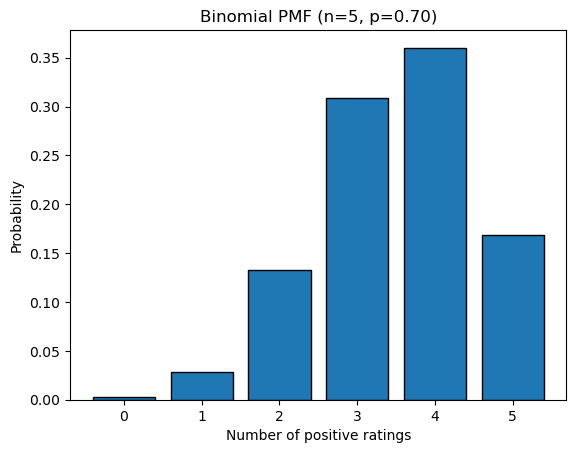

In [89]:
n, p, k = 5, 0.70, 3
exactly_3 = stats.binom.pmf(k, n, p)
at_least_3 = stats.binom.sf(2, n, p)  # P(X >= 3)
print(f"P(exactly 3 positives) = {exactly_3:.4f} ({exactly_3:.2%})")
print(f"P(at least 3 positives) = {at_least_3:.4f} ({at_least_3:.2%})")
values = np.arange(n + 1)
plt.bar(values, stats.binom.pmf(values, n, p), edgecolor="black")
plt.title("Binomial PMF (n=5, p=0.70)")
plt.xlabel("Number of positive ratings")
plt.ylabel("Probability")
plt.xticks(values)
plt.show()

**Interpretation:** “Exactly 3” means only the outcome 3; “at least 3” includes 3, 4, and 5. The binomial model assumes a fixed number of independent trials and a constant probability.

## 9. Normal distribution and Z-score
For illustration, suppose a separate delivery process is approximately normal with mean 7 days and SD 2 days. Calculate the Z-score for 11 days.

Z-score: 2.0
Normal-model probability of 11 days or more: 2.28%


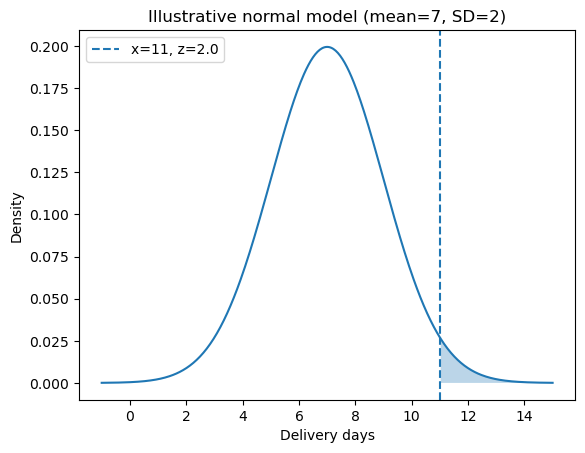

In [97]:
mu, sigma, x_value = 7, 2, 11
z = (x_value - mu) / sigma
tail_probability = stats.norm.sf(z)
print("Z-score:", z)
print(f"Normal-model probability of 11 days or more: {tail_probability:.2%}")
grid = np.linspace(mu - 4*sigma, mu + 4*sigma, 400)
density = stats.norm.pdf(grid, mu, sigma)
plt.plot(grid, density)
plt.fill_between(grid, density, where=(grid >= x_value), alpha=0.3)
plt.axvline(x_value, linestyle="--", label=f"x={x_value}, z={z}")
plt.title("Illustrative normal model (mean=7, SD=2)")
plt.xlabel("Delivery days")
plt.ylabel("Density")
plt.legend()
plt.show()

**Interpretation:** z=+2 means 11 days is two SDs above the assumed mean. Under this illustrative normal model, the upper-tail probability is about 2.28%. Do not apply this model to the actual skewed delivery data without evidence that it fits.

## 11. Central Limit Theorem (CLT)
Under suitable conditions, the distribution of repeated sample means becomes approximately normal as sample size increases. The original observations themselves do not need to become normal. Here we resample from the small observed delivery dataset as a demonstration.

Observed-data mean: 7.933
Theoretical SE for n=5: 2.182
Simulated SD of means for n=5: 2.179
Theoretical SE for n=25: 0.976
Simulated SD of means for n=25: 0.989


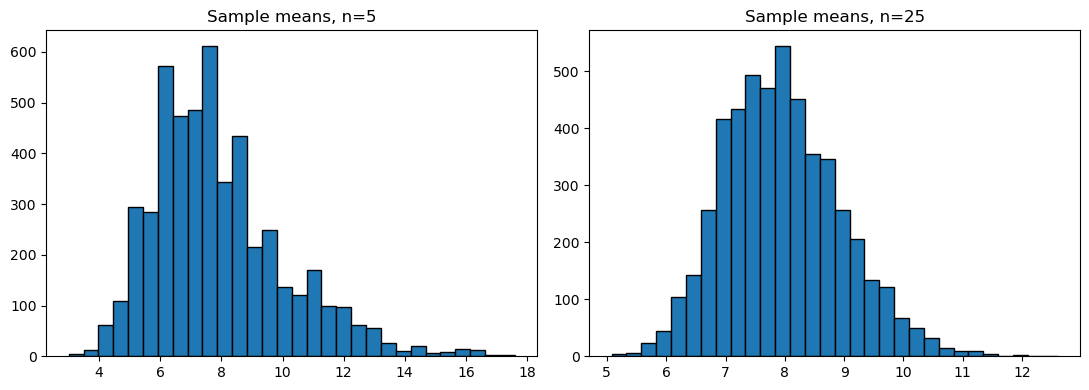

In [101]:
rng = np.random.default_rng(42)
population = df["delivery_days"].to_numpy()
num_samples = 5000
means_5 = np.array([rng.choice(population, 5, replace=True).mean() for _ in range(num_samples)])
means_25 = np.array([rng.choice(population, 25, replace=True).mean() for _ in range(num_samples)])
pop_sd = population.std(ddof=0)
print("Observed-data mean:", round(population.mean(), 3))
print("Theoretical SE for n=5:", round(pop_sd / np.sqrt(5), 3))
print("Simulated SD of means for n=5:", round(means_5.std(ddof=0), 3))
print("Theoretical SE for n=25:", round(pop_sd / np.sqrt(25), 3))
print("Simulated SD of means for n=25:", round(means_25.std(ddof=0), 3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(means_5, bins=30, edgecolor="black")
axes[0].set_title("Sample means, n=5")
axes[1].hist(means_25, bins=30, edgecolor="black")
axes[1].set_title("Sample means, n=25")
plt.tight_layout()
plt.show()

**Interpretation:** Larger samples generally yield less variable sample means; the standard error is approximately population SD / √n. This resampling exercise is illustrative because the source dataset is small.

## 12. Variance and standard deviation
Variance measures squared spread around the mean; SD is its square root and is in the original units. Use `ddof=0` for population-style calculation and `ddof=1` for sample calculation.

In [105]:
for col in ["delivery_days", "order_value_inr"]:
    print(f"\\n{col}")
    print("Population variance:", round(df[col].var(ddof=0), 3))
    print("Population SD:", round(df[col].std(ddof=0), 3))
    print("Sample variance:", round(df[col].var(ddof=1), 3))
    print("Sample SD:", round(df[col].std(ddof=1), 3))

\ndelivery_days
Population variance: 23.796
Population SD: 4.878
Sample variance: 24.616
Sample SD: 4.961
\norder_value_inr
Population variance: 722751.222
Population SD: 850.148
Sample variance: 747673.678
Sample SD: 864.681


**Interpretation:** SD summarizes spread but is sensitive to extremes. With skewed data, interpret it together with the median and IQR.

## 13. Covariance and correlation
Covariance describes directional co-movement. Pearson correlation standardizes covariance and measures linear association from −1 to +1. These are associations, not proof of causation.

Sample covariance: -2.352
Pearson correlation: -0.461


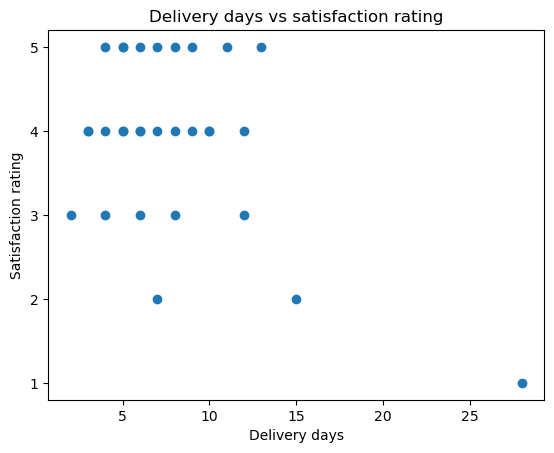

In [109]:
cov = df["delivery_days"].cov(df["satisfaction_rating"])
corr = df["delivery_days"].corr(df["satisfaction_rating"])
print("Sample covariance:", round(cov, 3))
print("Pearson correlation:", round(corr, 3))
plt.scatter(df["delivery_days"], df["satisfaction_rating"])
plt.title("Delivery days vs satisfaction rating")
plt.xlabel("Delivery days")
plt.ylabel("Satisfaction rating")
plt.yticks([1,2,3,4,5])
plt.show()

**Interpretation:** A negative correlation means longer delivery times tend to be associated with lower ratings in this sample. Outliers can affect Pearson correlation, and observational data alone cannot prove that delivery time causes the rating.

## 14. Coefficient of variation (CV)
CV is standard deviation divided by mean, expressed as a percentage. It compares relative spread when means are positive and meaningfully away from zero.

In [113]:
for col in ["delivery_days", "order_value_inr"]:
    mean_value = df[col].mean()
    sd_value = df[col].std(ddof=1)
    cv = sd_value / mean_value * 100
    print(f"{col}: mean={mean_value:.2f}, sample SD={sd_value:.2f}, CV={cv:.2f}%")

delivery_days: mean=7.93, sample SD=4.96, CV=62.54%
order_value_inr: mean=1382.33, sample SD=864.68, CV=62.55%


**Interpretation:** Higher CV means more variability relative to the mean, where CV is meaningful. Avoid it for means near zero or arbitrary-origin scales.

## 15. Final business summary

When writing the conclusion, include:
1. Typical delivery and order values (median as well as mean).
2. Spread using IQR and SD.
3. Potential outliers to investigate, not automatically delete.
4. Histogram shape and skewness.
5. PMF proportions for ratings and CDF proportions meeting delivery thresholds.
6. Binomial assumptions before using probabilities.
7. Sampling method and possible bias.
8. Covariance/correlation as association, not causation.
9. Next step: collect a larger representative sample and use a randomized A/B test if you need to estimate whether an intervention causes an improvement.

**Core lesson:** Each technique answers a different question—center, spread, shape, probability, sampling uncertainty, association, or causal effect.